# NCY Taxi Trips - Data preparation 


## Objective 

The objective of this notebook is to perform an initial assessment of the NYC Taxi Trips dataset.

This phase focuse on:

- Undertanding the dataset structure
- Identifying missing values 
- Detecting duplicate records
- Checking data types 
- Performing initial data quality assessment 


Author: Mohamed Aliou Diallo

Project: Smart City Analytics

In [5]:
import pandas as pd
import numpy as np

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [7]:
df = pd.read_csv('../data/raw/NYC.csv')

print(f'Dataset shape: {df.shape}')

df.head()

Dataset shape: (1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 122.4+ MB


## Dataset Overview 

This section provides information about:

- number of rows 
- number of columns 
- data types 
- missing values 


In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
vendor_id,1458644.0,1.534950,0.498777,1.000000,1.000000,2.000000,2.000000,2.000000e+00
passenger_count,1458644.0,1.664530,1.314242,0.000000,1.000000,1.000000,2.000000,9.000000e+00
pickup_longitude,1458644.0,-73.973486,0.070902,-121.933342,-73.991867,-73.981743,-73.967331,-6.133553e+01
pickup_latitude,1458644.0,40.750921,0.032881,34.359695,40.737347,40.754101,40.768360,5.188108e+01
dropoff_longitude,1458644.0,-73.973416,0.070643,-121.933304,-73.991325,-73.979752,-73.963013,-6.133553e+01
dropoff_latitude,1458644.0,40.751800,0.035891,32.181141,40.735885,40.754524,40.769810,4.392103e+01
trip_duration,1458644.0,959.492273,5237.431724,1.000000,397.000000,662.000000,1075.000000,3.526282e+06


## Statistical Summary 

Descriptive statistics for numeric variables

In [22]:
missing_values = df.isnull().sum()

print (
    f'Number of missing values:\n{missing_values }'
)

Number of missing values:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64


In [15]:
missing_percentage = (missing_values / len(df)) * 100

missing_percentage


id                    0.0
vendor_id             0.0
pickup_datetime       0.0
dropoff_datetime      0.0
passenger_count       0.0
pickup_longitude      0.0
pickup_latitude       0.0
dropoff_longitude     0.0
dropoff_latitude      0.0
store_and_fwd_flag    0.0
trip_duration         0.0
dtype: float64

## Missing Values Assessment 

Identify columns with missing observations and evaluate their impact 

No missing values were detected in the dataset 

The dataset is complete and does not require imputation stategies 

In [16]:
duplicates = df.duplicated().sum()

print(
    f'Number of duplicate rows: {duplicates}'
)

Number of duplicate rows: 0


## Duplicate Detection 

Check if duplicate records exist in the dataset 

No duplicate records were identified 

The dataset does not require duplicate removal

In [17]:
df.dtypes

id                     object
vendor_id               int64
pickup_datetime        object
dropoff_datetime       object
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag     object
trip_duration           int64
dtype: object

## Variable Types 

Review the type of each variable before preprocessing 

In [21]:
target = 'trip_duration'

print(
    f'Target variable: {target}'
)

df[target].describe()

Target variable: trip_duration


count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.620000e+02
75%      1.075000e+03
max      3.526282e+06
Name: trip_duration, dtype: float64

## Target Variable 

The goal of the machine learning model will be to predict trip duration 

# Initial Data Qaulity Assessment 
 
## Dataset Overview 

- Total Records: 1,458,644
- Total Features: 11
- Missing Values: 0
- Duplicate Records: 0

## Data Types

The dataset contains:

- Numerical variables
- Categorical variables
- Datetime variables 

## Data Quality Fingings

The dataset is generaly clean and complete.

No missing values were detected.

No duplicate records were found.

However, potential outliers were identified in:

- Geographic coordinates (latitude and longitude)
- Trip duration 

These anomalies will be investigated during the data cleaning phase 

## Next Steps

1. Convert datatime columns
2. Perform feature engineering 
3. Detect outilers
4. Clean invalied observations
5. Prepare data for exploratory analysis



In [23]:
# convert the pickup and dropoff datetime columns to datetime format

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime']
)

df['dropoff_datetime'] = pd.to_datetime(
    df['dropoff_datetime']
)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   id                  1458644 non-null  object        
 1   vendor_id           1458644 non-null  int64         
 2   pickup_datetime     1458644 non-null  datetime64[ns]
 3   dropoff_datetime    1458644 non-null  datetime64[ns]
 4   passenger_count     1458644 non-null  int64         
 5   pickup_longitude    1458644 non-null  float64       
 6   pickup_latitude     1458644 non-null  float64       
 7   dropoff_longitude   1458644 non-null  float64       
 8   dropoff_latitude    1458644 non-null  float64       
 9   store_and_fwd_flag  1458644 non-null  object        
 10  trip_duration       1458644 non-null  int64         
dtypes: datetime64[ns](2), float64(4), int64(3), object(2)
memory usage: 122.4+ MB


In [25]:
# Extracting date and time features from the pickup_datetime column

df['pickup_year'] = df['pickup_datetime'].dt.year

df['pickup_month'] = df['pickup_datetime'].dt.month

df['pickup_day'] = df['pickup_datetime'].dt.day

df['pickup_hour'] = df['pickup_datetime'].dt.hour

df['pickup_weekday'] = (
    df['pickup_datetime'].dt.day_name()
)

In [26]:
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_year,pickup_month,pickup_day,pickup_hour,pickup_weekday
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,2016,3,14,17,Monday
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,2016,6,12,0,Sunday
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,2016,1,19,11,Tuesday
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,2016,4,6,19,Wednesday
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,2016,3,26,13,Saturday


# Outlier Detection

This section aims to identify abnormal observations that may negatively affect data analysis and machine learning models.

The analysis focuses on:

- Trip duration
- Passenger count
- Geographic coordinates 

In [27]:
df['trip_duration'].describe()

count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.620000e+02
75%      1.075000e+03
max      3.526282e+06
Name: trip_duration, dtype: float64

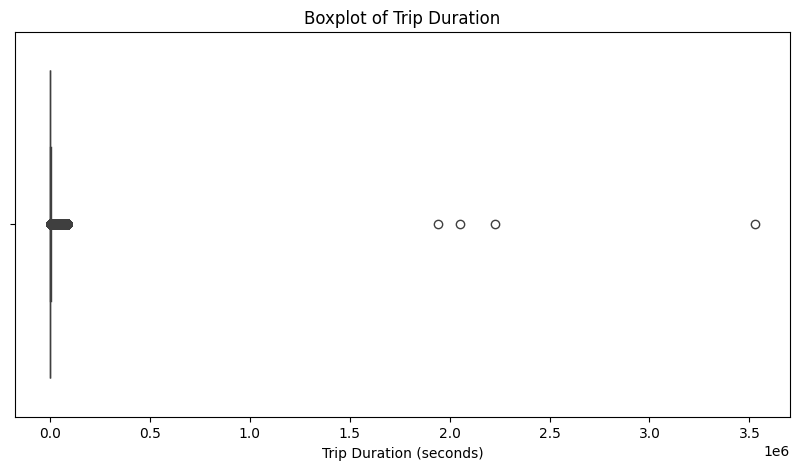

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.boxplot(
    x=df['trip_duration']
)

plt.title('Boxplot of Trip Duration')

plt.xlabel('Trip Duration (seconds)')

plt.show()

In [30]:
df["trip_duration"].nlargest(10)

978383     3526282
924150     2227612
680594     2049578
355003     1939736
1234291      86392
295382       86391
73816        86390
59891        86387
1360439      86385
753765       86379
Name: trip_duration, dtype: int64

In [31]:
longest_indices = df["trip_duration"].nlargest(10).index
df.loc[longest_indices]

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_year,pickup_month,pickup_day,pickup_hour,pickup_weekday
978383,id0053347,1,2016-02-13 22:46:52,2016-03-25 18:18:14,1,-73.783905,40.648632,-73.978271,40.750202,N,3526282,2016,2,13,22,Saturday
924150,id1325766,1,2016-01-05 06:14:15,2016-01-31 01:01:07,1,-73.983788,40.742325,-73.985489,40.727676,N,2227612,2016,1,5,6,Tuesday
680594,id0369307,1,2016-02-13 22:38:00,2016-03-08 15:57:38,2,-73.921677,40.735252,-73.984749,40.759979,N,2049578,2016,2,13,22,Saturday
355003,id1864733,1,2016-01-05 00:19:42,2016-01-27 11:08:38,1,-73.789650,40.643559,-73.956810,40.773087,N,1939736,2016,1,5,0,Tuesday
1234291,id1942836,2,2016-02-15 23:18:06,2016-02-16 23:17:58,2,-73.794525,40.644825,-73.991051,40.755573,N,86392,2016,2,15,23,Monday
295382,id0593332,2,2016-05-31 13:00:39,2016-06-01 13:00:30,1,-73.781952,40.644688,-73.993874,40.745926,N,86391,2016,5,31,13,Tuesday
73816,id0953667,2,2016-05-06 00:00:10,2016-05-07 00:00:00,1,-73.996010,40.753220,-73.979027,40.740601,N,86390,2016,5,6,0,Friday
59891,id2837671,2,2016-06-30 16:37:52,2016-07-01 16:37:39,1,-73.992279,40.749729,-73.962524,40.800770,N,86387,2016,6,30,16,Thursday
1360439,id1358458,2,2016-06-23 16:01:45,2016-06-24 16:01:30,1,-73.782089,40.644806,-73.985016,40.666828,N,86385,2016,6,23,16,Thursday
753765,id2589925,2,2016-05-17 22:22:56,2016-05-18 22:22:35,4,-74.006111,40.734680,-73.958809,40.815449,N,86379,2016,5,17,22,Tuesday


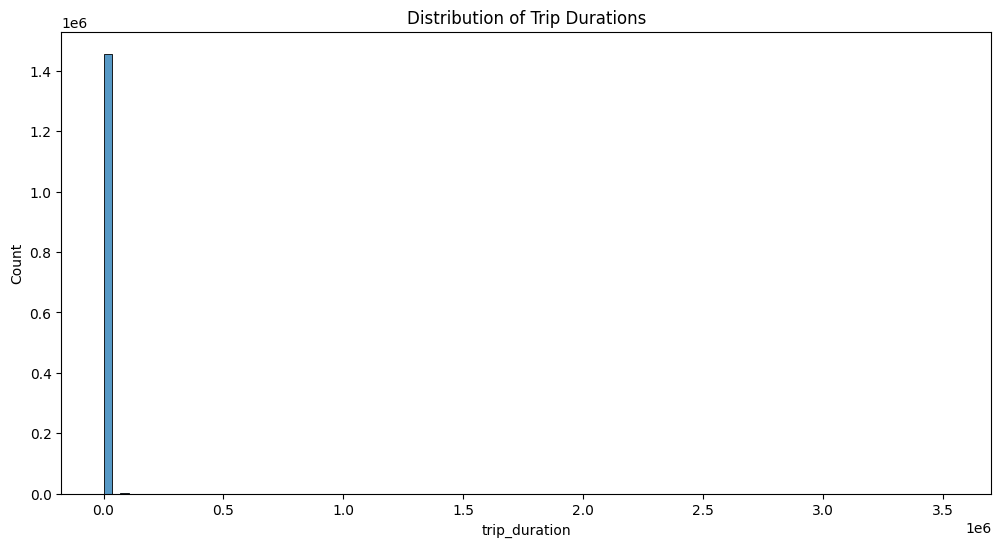

In [32]:
plt.figure(figsize=(12,6))

sns.histplot(
    df['trip_duration'],
    bins=100
)

plt.title('Distribution of Trip Durations')

plt.show()

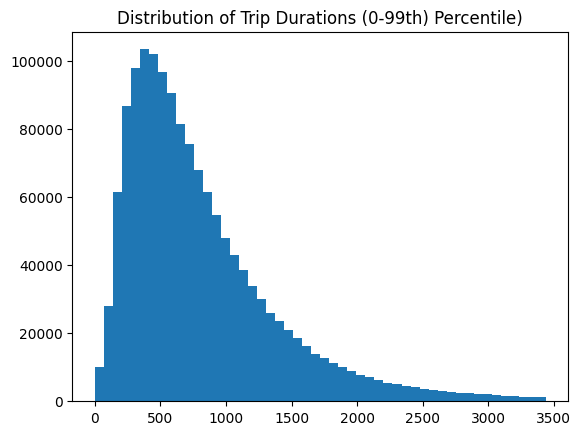

In [37]:
limit = df['trip_duration'].quantile(0.99)

plt.hist(
    df['trip_duration'],
    bins=50 ,
    range=(0, limit)
)
plt.title('Distribution of Trip Durations (0-99th) Percentile)')

plt.show()

In [33]:
Q1 = df['trip_duration'].quantile(0.25)

Q3 = df['trip_duration'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR 

print(f'Q1: {Q1}, Q3: {Q3}, IQR: {IQR}')

print(f'lower_bound: {lower_bound}, upper_bound: {upper_bound}')



Q1: 397.0, Q3: 1075.0, IQR: 678.0
lower_bound: -620.0, upper_bound: 2092.0


In [35]:
outliers = df[
    (df['trip_duration'] < lower_bound)
    |
    (df['trip_duration'] > upper_bound)

]

print(
    f'Number of outliers: {len(outliers)}'
)

Number of outliers: 74220


In [39]:
df['trip_duration'].sort_values(
    ascending=False
).head(20)

978383     3526282
924150     2227612
680594     2049578
355003     1939736
1234291      86392
295382       86391
73816        86390
59891        86387
1360439      86385
753765       86379
1221666      86378
91717        86378
66346        86377
1138915      86377
1269316      86369
172662       86369
779030       86369
1284067      86369
1233528      86367
1213613      86367
Name: trip_duration, dtype: int64

In [41]:
df[
    df['trip_duration'] > 7200
].shape

(2253, 16)

In [44]:
df_clean = df[
    (df['trip_duration'] >= 60)
    & 
    (df['trip_duration'] <= 7200)
].copy()

In [45]:
print(
    f'original dataset shape: {df.shape} \n cleaned dataset shape: {df_clean.shape}'
)

original dataset shape: (1458644, 16) 
 cleaned dataset shape: (1447796, 16)


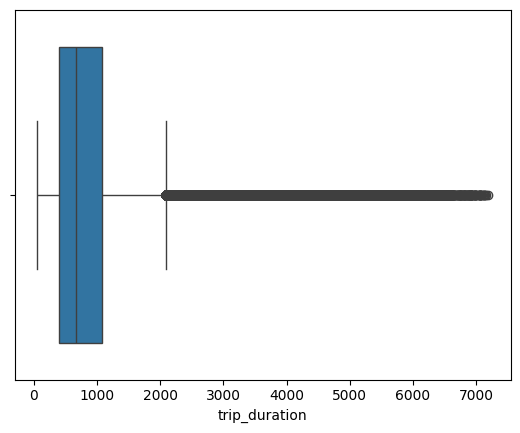

<Figure size 1200x600 with 0 Axes>

In [46]:
sns.boxplot(
    x=df_clean['trip_duration']
)

plt.figure(figsize=(12,6))

plt.show()

# Outlier Treatment

Outliers were detected using the Interquartile Range (IQR) method.

The analysis identified 74,220 observations outside the accepted range.

For modeling purposes, trip durations were restricted to realistic taxi rides between:

- 60 seconds (1 minute)
- 7,200 seconds (2 hours)

This approach improves data quality and reduces the impact of extreme observations on statistical analysis and machine learning models.

# Geographic Coordinates Validation

In [47]:
coordinates = [
    'pickup_longitude', 
    'pickup_latitude', 
    'dropoff_longitude', 
    'dropoff_latitude'
]

df_clean[coordinates].describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_longitude,1447796.0,-73.973626,0.070765,-121.933342,-73.991875,-73.981766,-73.967430,-61.335529
pickup_latitude,1447796.0,40.750974,0.032670,34.359695,40.737411,40.754135,40.768368,51.881084
dropoff_longitude,1447796.0,-73.973545,0.070504,-121.933304,-73.991325,-73.979767,-73.963097,-61.335529
dropoff_latitude,1447796.0,40.751852,0.035725,32.181141,40.735943,40.754559,40.769829,43.921028


In [49]:
invalide_coordinates = df_clean[
    (df_clean['pickup_longitude'] < - 75 )
    |
    (df_clean['pickup_longitude'] > - 73 )
    |
    (df_clean['pickup_latitude'] < 40 )
    |
    (df_clean['pickup_latitude'] > 42 )
    
]

print(
    f'invalide pickup coordinates: {len(invalide_coordinates)}'
)

invalide pickup coordinates: 28


In [50]:
df_clean = df_clean[
    (df_clean["pickup_longitude"].between(-75, -73))
    &
    (df_clean["pickup_latitude"].between(40, 42))
    &
    (df_clean["dropoff_longitude"].between(-75, -73))
    &
    (df_clean["dropoff_latitude"].between(40, 42))
]

print(
    f'cleaned dataset shape after removing invalid coordinates: {df_clean.shape}'
)

cleaned dataset shape after removing invalid coordinates: (1447755, 16)


In [51]:
df_clean.to_csv('../data/processed/NYC_cleaned.csv',
                index=False
)
                

In [52]:
print(
    f'Cleaned dataset shape: {df_clean.shape}'
)

Cleaned dataset shape: (1447755, 16)
